## Module 3: Computational Drug Discovery Project 

## Project Goal:


The goal of this project is to develop a GLPI agonist drug that performs better than competitors Ozempic and Wegovy. To demonstrate our understanding of the pharmacodynamics and pharmacokinetics of GLOP agonist drugs we conducted the three following analyses. 
1. We compared models to find the best representation of the provided data that lists, concentration of Cavalitide and the corresponding fraction of receptors activated. Once the most accurate model was found we used it to predict the concentration of Cavalitide at which the fraction of activation would be 50%, this is known as the Kd value. 
2. We then modeled how the drug reacted to the body 
3. Finally, we modelled the pharmacodynamics and pharmacokinetics of Cavalitide to predict the change in receptors activated over the course of treatment. We adjusted the drug administration to create a model that plateaus at 90% activation. 

So overall, we want to ask, how can we best create a drug that activates receptors, minimizes side effects, and creates steady, lasting blood concentrations?


## Disease Background: 
According to a CDC survey, in the United States the prevalence of obesity in 2021-2023 was 40.3%(Emmerich, Fryar, Stierman, & Ogden, 2024). Obesity is the result of an individual consuming more calories than they can burn. Genetic, behavioral metabolic and hormonal influence can increase the risk for obesity (Mayo Clinic Staff, 2025). The most noticeable symptom of obesity is the excess amount of body fat. As a patient's obesity persists inflammation in the body increases and causes long-lasting metabolic changes to the body (CDC, 2026). Patients can also develop heart disease, certain types of cancers, type 2 diabetes, digestive conditions, sleep apnea, osteoarthritis, and steatotic liver disease. BMI (Body Mass Index) is the most common way to diagnose obesity. A BMI of 30.0-higher signifies obesity (Mayo Clinic Staff, 2025). Obesity can be treated with lifestyle changes, weight-loss programs, weight-loss medicines, weight loss surgery and weight-loss devices (“Treatment for Overweight & Obesity,” 2025). Weight-loss medicines are commonly GLP-1 agonists which mimic the natural GLP-1 hormone that is released after an individual eats, reducing hunger. They are the most common treatment to be covered by insurance. 

Obesity is multifactorial and multiple elements contribute to its development and pathogenesis. The regulation of the amount of calories the body craves (intake) versus needs (expenditure) is reliant on hormones. Neurotransmitters and metabolic signals control energy and therefore feeding behavior. Fat cell development is controlled by hormones, and their activation of a variety of receptors on the cell (Lustig et al., 2022). 

While there is a new wave of weight loss drugs that have proven to be very effective, the side effects of such drugs are still being revealed. Current treatments are focused on solely weight loss and there is a need for treatments that are focused on preservation of muscle and bone as well as providing a more tailored approach for each patient (MacMillan, 2026). 


## Task 1: Fit a receptor binding model for Cavalitide (LAYLA):

Task: Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor. You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 

In this section, we created code that modeled the Cavalitide binding data, plotted it, fit a line of good fit to it, and used that line to produce a Kd value. At the end of the code is the provided graphs and conclusion. The CSV of the Cavalitide binding data can be found in this repository. 

The code below breaks down the steps of creating a pharmocodynamics model for Cavalitide in it's binding relationship to the receptors.

In [ ]:
# First, we want to do 'set-up' work

# Let's import neccessary packages:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Now, define the function for active receptors (Fact).
def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
   
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # default 0.38 L2, 
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

In [10]:
# Now, bring in the Cavalitide data from the CSV file
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

In [11]:
# So, with all of the data loaded, it is now try to attempt optimaization. For this analysis, we decided to try both the Brute force approach 
# and the curve_fit approach, and then at the end will conclude which was more accurate based on the SSE (sum of squared errors) values.

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try


# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)


Fitted Kd2 = 0.077 nM (SSE = 0.0052)
Brute-force Kd2 = 0.074 nM (SSE = 0.0054)


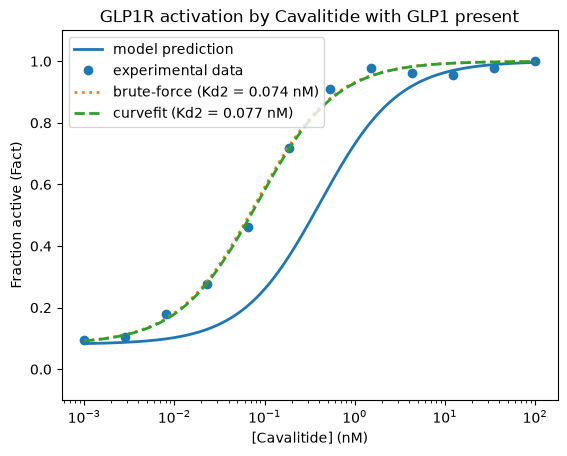

In [13]:
# Now, let's plot the results of both approaches and compare to the experimental data

# displaying the results of both approaches
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")
plt.figure()
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# creating a plot to compare the model predictions to the experimental data
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
label="model prediction")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")
plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.show()

Looking at the above data, both the Brute Force and the curve fit yielded very similar values. However, the SSE is smaller with the Curve Fit method, and so we will use that value for the Kd, which is 0.077. This Kd compared to that of the semiglutide, which is .38, is significantly lower. This means that the Cavalitide is a significantly better binder. Looking at the graph, this is made clear. The blue line is the traditional model, whereas the dotted green and orange are shifted to the left. These lower values means that Cavalitide is able to active more receptors with much less concentration. This is advantageous for the ability to provide less dosage, and therefore lower side effects, but does mean that the risk of overdose or weaning off of the mediciation may be more complicated. 

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment (LAYLA)

Now, we are going to consider how the body interacts with Cavalitide over time, in comparison to the other similar drug forms, Wegovy and Ozempic. An important distinction in this program is how subcutaneous injections (like Ozempic) differ from oral pills (like Wegovy and Cavalitide). 

In this portion, we ran simulations for the amount of Wegovy and Ozempic present in the blood and other body depots over time given certain parameters like dosage and dosage spacing. From there, we then ran similar analysis on Cavalitide and it's concentrations. Finally, this granted the ability to edit certain parameters to ensure that the the dosing achieved it's goal of a blood concentration around 0.5 nM. A conclusion and analysis is given at the end.

In [14]:
# First, we want to consider how Ozempic and Wegovy work in the body. Here, let's look at graphs of both of these:

# begin by importing the necessary packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate

In [15]:
# These are the two drugs we want to simulate, and will be graphing them side by side.
drugA = 'Ozempic'
drugB = 'Wegovy'

# product-specific parameters, divided into a dictionary for each drug. These parameters are based on the pharmacokinetics of each drug.
products = {
    'Ozempic': dict(Favailable=0.89, # bioavailability
                    ka=0.029, # 1/h, absorption rate
                    D=2.0, # mg per dose
                    interval=168, # h between doses (weekly)
                    n_doses=8, # number of doses
                    depot='subcutaneous'),

    'Wegovy': dict(Favailable=0.01,
                    ka=0.0029,
                    D=25, # mg
                    interval=24, # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}

# calling each drug and assigning the parameters to variables for use in the simulation.
a = products[drugA]
Favailable, ka, D = a['Favailable'], a['ka'], a['D']
interval, n_doses, depot = a['interval'], a['n_doses'], a['depot']

b = products[drugB]
Favailable_B, ka_B, D_B = b['Favailable'], b['ka'], b['D']
interval_B, n_doses_B, depot_B = b['interval'], b['n_doses'], b['depot']

In [16]:
# shared model parameters
ke = 0.0039 # 1/h, elimination rate
V = 10.8 # L
MW = 4113.6 # g/mol
Ffree = 0.01 # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1 # h, Euler step size
def make_ode(ka):
    def ODEfunc(t, y):
        Asc, Cc = y
        dAsc = -ka*Asc
        dCc = ka*Asc/V - ke*Cc
        return [dAsc, dCc]
    return ODEfunc

# this code creates a function to simulate the pharmacokinetics of the drugs based on their parameters. It uses the ODE solver to 
# compute the concentration of the drug in the depot and in the central compartment over time, 
# taking into account multiple doses and the specified dosing interval. The results are returned as time points, 
# depot concentrations, and central compartment concentrations in nM.
def simulate(D, n_doses, interval, dt, Favailable, ka):
    ODEfunc = make_ode(ka)
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += Favailable * D

        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        sol = scipy.integrate.solve_ivp(
            ODEfunc, (t0, t0 + interval), y, t_eval=t_seg
        )
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# calling the simulate function for both drug and assigning the results to variables for plotting.
t, Asc, Cc = simulate(D, n_doses, interval, dt, Favailable, ka)
t_b, Asc_b, Cc_b = simulate(D_B, n_doses_B, interval_B, dt, Favailable_B, ka_B)

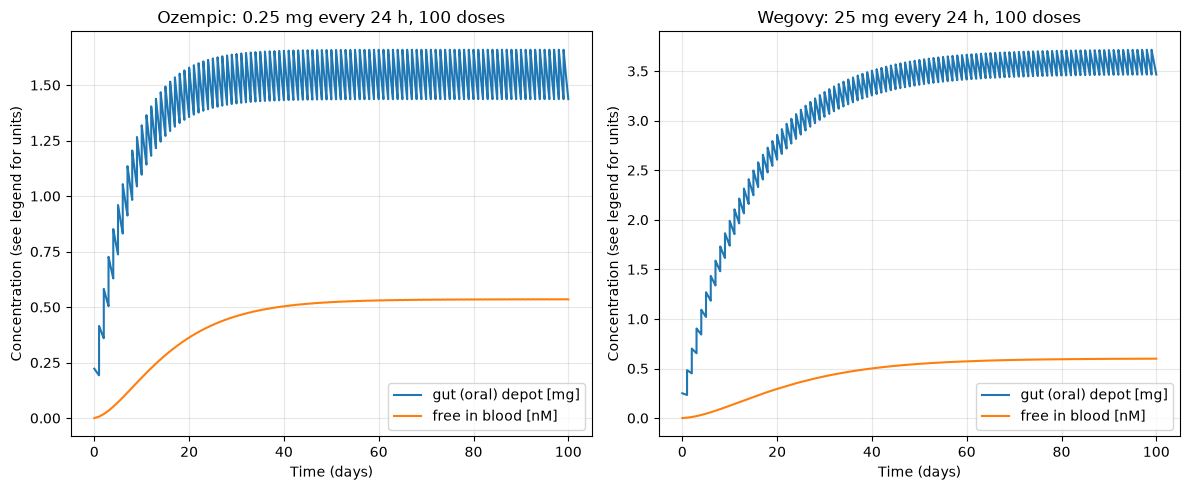

In [23]:
# plot both drugs side by side!
plt.figure(figsize=(12, 5))

# The plot for Ozempic
plt.subplot(1, 2, 1)
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree * Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (see legend for units)")
plt.title(f"{drugA}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)

# Plot for Wegovy
plt.subplot(1, 2, 2)
plt.plot(t_b / 24, Asc_b, label=f"{depot_B} depot [mg]")
plt.plot(t_b / 24, Ffree * Cc_b, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (see legend for units)")
plt.title(f"{drugB}: {D_B} mg every {interval_B} h, {n_doses_B} doses")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

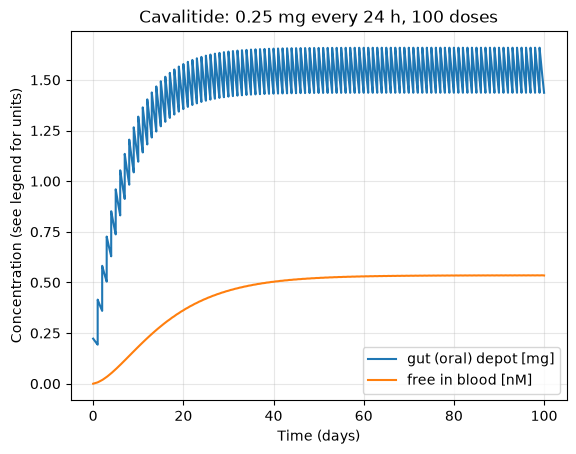

In [34]:
# Now that we have looked at the pharmacokinetics of Ozempic and Wegovy, we want to look at a new drug, Cavalitide. 
# This drug is similar to semaglutide, but has a higher bioavailability and faster absorption rate. 
# We will simulate the pharmacokinetics of Cavalitide using the same model as before.

drug = "Cavalitide"

# product-specific parameters
products = {
    'Cavalitide': dict(Favailable=0.89,
                       ka=0.006,
                       D=0.25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
}

p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039 # 1/h, elimination rate
V = 10.8 # L
MW = 4113.6 # g/mol
Ffree = 0.01 # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1 # h, Euler step size
def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt)) # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D # absorbed fraction of dose enters the depot

        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y

        # explicit Euler: y[n+1] = y[n] + dt * f(t[n], y[n])
        # for n in range(n_steps):
        #     y_seg[:, n + 1] = y_seg[:, n] + dt * np.array(
        #         ODEfunc(t_seg[n], y_seg[:, n])
        #     )

        # Euler's via the formula! 
        sol = scipy.integrate.solve_ivp(
            ODEfunc,
            (t0, t0 + interval),
            y,
            t_eval=t_seg,
        )
        y_seg = sol.y
        
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy() # carry state into next interval

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM


#  run simulation
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# plot 
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (see legend for units)")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Conclusion: Cavalitide has a higher bioavailability and faster absorption rate compared to Wegovy, resulting in higher peak concentrations and more rapid onset of action. In order to keep the blood concentration around 0.5 nM, the dose should be at a rate of 0.5 mg, taken every other day, or lower the dose to 0.25 daily. The second route provides a more even expereince for the user, as there are not as many peaks in the gut depot. 

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment



The following code conducts the previous two tasks solely for the Cavalitide. In the first task the brute force and curvefit model were compared to see which more accurately represented the provided Cavalitide data. It was determined that the curvefit model was more accurate because it had a smaller sum of squared error (SSE = 0.0052). Therefore in task three the curvefit model is used to determine the Kd value of Cavalitide. 


A function FActC is created which calculates the fraction of receptors activated solely with Cavalitide. The function uses the ligand concentration calculated in task 2, and the kd value found in task 1. 


The last graph (graph 4) models the adjusted parameters for the Cavaltide to achieve 90% activation at 100 days. The original steady state (recorded by taking the Fact percentage at 100 days) was approximately 0.89. This was observed from graph three of task 3. To increase the Fact at 100 days the dosage of Cavalitide was increased from 0.25 to 0.3. 


Increasing the dosage of Cavalitide has a series of implications. It increases the chances of side effects and the severity of such side effects because there is more foreign substance in the body. If manufacturing costs increase with increased production, a single Cavalitide dosage would also be more expensive reducing the accessibility of the drug. 


Fitted Kd2 = 0.077 nM (SSE = 0.0052)


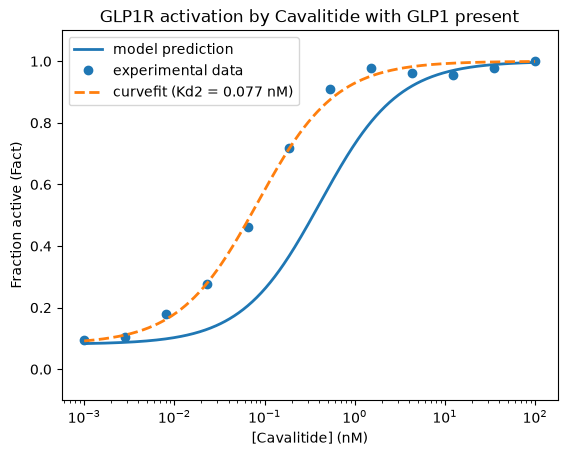

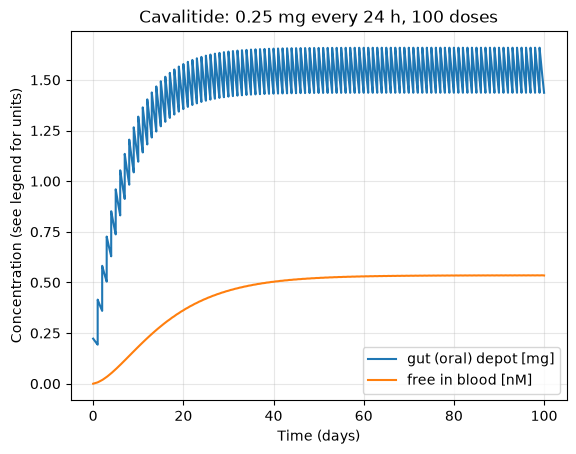

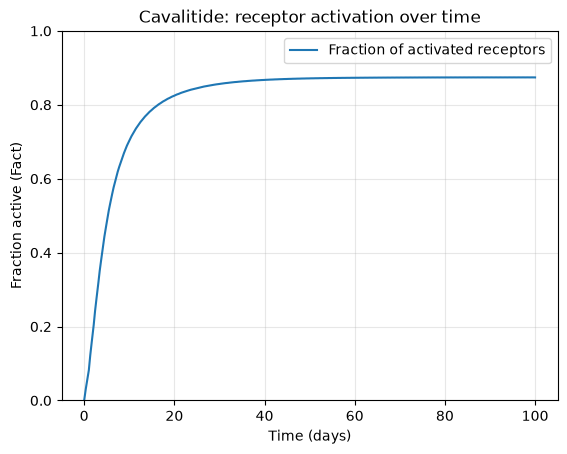

Adjusted dose to achieve 90% activation at day 100: 0.3 mg


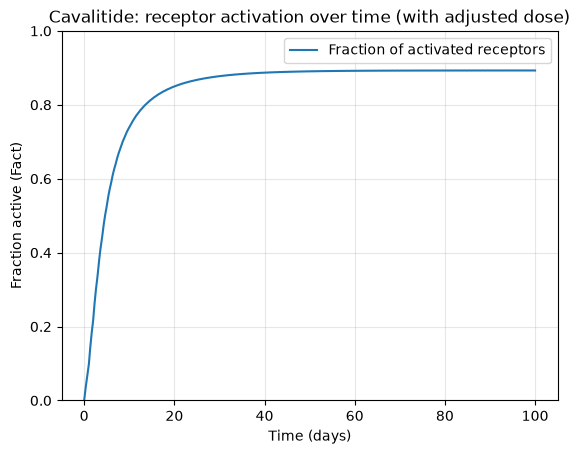

In [37]:
# Task 3: How the fraction of activated receptors cahnges over time 

# fit_semaglutide_GLP1R.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import scipy.integrate


def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
   
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)
# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # default 0.38 L2, semaglutide (to fit)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]


# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)


print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")
plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
label="model prediction")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")
plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.show()

# Only pharamacokinetics of Cavalitide. 
drug = "Cavalitide"

# product-specific parameters
products = {
    'Cavalitide': dict(Favailable=0.89,
                       ka=0.006,
                       D=0.25,
                       DA=0.30, #adjusted dose to achieve 90% activation at day 100
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D, DA = p['Favailable'], p['ka'], p['D'], p['DA']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# model parameters
ke = 0.0039 # 1/h, elimination rate
V = 10.8 # L
MW = 4113.6 # g/mol
Ffree = 0.01 # rest of semaglutide bound to albumin

#finding fraction activated just for cavalitide using the ligand concentration found from the pharmacokinetics model and the Kd2 value found from the curve fitting.
def FactC(L, Kd):
    """Fractional receptor activation: L / (Kd + L)"""
    return L / (Kd + L)

# simulation parameters
dt = 0.1 # h, Euler step size
def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt)) # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D # absorbed fraction of dose enters the depot

        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y

        # explicit Euler: y[n+1] = y[n] + dt * f(t[n], y[n])
        # for n in range(n_steps):
        #     y_seg[:, n + 1] = y_seg[:, n] + dt * np.array(
        #         ODEfunc(t_seg[n], y_seg[:, n])
        #     )

        # Euler's via the formula! 
        sol = scipy.integrate.solve_ivp(
            ODEfunc,
            (t0, t0 + interval),
            y,
            t_eval=t_seg,
        )
        y_seg = sol.y
        
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy() # carry state into next interval

    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    L = Ffree*Cc_nM # free semaglutide in blood [nM]
    Fact_out = FactC(L, Kd2_fit) # fraction of activated receptors 
    return t, Asc_out, Cc_nM, Fact_out


# --- run --- Fact_out was added to this function. 
t, Asc, Cc, Fact_out = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (see legend for units)")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#seperate graph to display how Fact changes over time. 
plt.figure()
plt.plot(t / 24, Fact_out, label="Fraction of activated receptors")
plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title(f"{drug}: receptor activation over time")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#Adjusting the paramters of the simulation so that at day 100 there is 90% activation 
#this was done by using a different dosage, the variable is DA. 
def simulateA(DA, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt)) # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*DA # absorbed fraction of dose enters the depot

        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y

        # explicit Euler: y[n+1] = y[n] + dt * f(t[n], y[n])
        # for n in range(n_steps):
        #     y_seg[:, n + 1] = y_seg[:, n] + dt * np.array(
        #         ODEfunc(t_seg[n], y_seg[:, n])
        #     )

        # Euler's via the formula! 
        sol = scipy.integrate.solve_ivp(
            ODEfunc,
            (t0, t0 + interval),
            y,
            t_eval=t_seg,
        )
        y_seg = sol.y
        
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy() # carry state into next interval

    t2 = np.concatenate(t_out)
    Asc_out2 = np.concatenate(Asc_out)
    Cc_out2 = np.concatenate(Cc_out)
    Cc_nMM2 = Cc_out2 * 1e-3 / MW * 1e9
    L = Ffree*Cc_nMM2 # free semaglutide in blood [nM]
    Fact_out2 = FactC(L, Kd2_fit) # fraction of activated receptors 
    return t2, Asc_out2, Cc_nMM2, Fact_out2

t2, Asc2, Cc2, Fact_out2 = simulate(DA, n_doses, interval, dt)
print(f"Adjusted dose to achieve 90% activation at day 100: {DA} mg")
#show new graph with adjusted dosage to achieve 90% activation at day 100.
plt.figure()
plt.plot(t2 / 24, Fact_out2, label="Fraction of activated receptors")
plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title(f"{drug}: receptor activation over time (with adjusted dose)")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The clinical benefits from this 90% activation include a very effective dosage for maximum therapuetic benefit, but not a disproportionate or overly loaded dose that could result in severe side effects. By knowing key factors like Kd values, absoprtion and these models, we are able to hit this 'sweet spot' value in our simulations. Beyond a 90% yield, law of diminishing returns kicks in, creating a nonideal increase risk of side effect for each extra percentage of activated receptors. So, our dosing strategy as suggested above will be the most clinically helpful according to these models. However, as always, these results must be corroborated by levels of clinical trial. 

## Conclusions:

This project analyses the proposed Cavalitide over 3 seperate tasks. For each task, we have analyzed the result from that task, and then analyzed the drug as a whole at the end. 

Task 1: The Cavalitide's Kd value is much lower than that of Semiglutide, and so it provides much tighter overall binding.

Task 2: For the dosing to give a constant blood concentration of around 0.5 nM, the dose itself only needs to 0.25 mg every day. This is due to the tighter binding overall.

Task 3: This tasks aims to produce a Fraction of activated receptors of 90%. In order to do this, our analysis found that the drug dosage should be at .3 mg daily. 

Overall, this means that we deduced Cavalitide would be an optimal drug based on a couple key factors. One, it has a lower dosage needed than Wegovy or Ozempic, possibly lowering negative side effects. The pill could be small, meaning it is more approachable and accessible to users, and taken once daily. Even with this small, lower dose pill, we could expect Cavalitide to remain at concnetrations of around .5 nM in the blood, and for flucations in the gut depot to be relatively constant, at peaks of around 1.4 to 1.6. Overall, this makes Cavalitide an exciting new prospective drug. 

## Verify and Validate 

# Verify 
The primary way we verified our results was comparing them to our peers in class who were assigned the same assignment. We determined after the presentations on Tuesday that our answers were similar to our peers and in that respect valid. We also verified our sources with published research. 
A systematic review of 17 different studies focused on the pharmacokinetics of semaglutide found that with increased dosage came increased long-term concentration of semaglutide in patients' blood (Yang & Yang, 2024). This behaviour of a GLP1 agonist agrees with our results that found that by increasing our dosage we could increase the percentage of GLP-1 receptors activated in the long term. Both results prove that the human body can hold onto GLP-1 agonist long term and that this behaviour is dependent on the amount of drug administered. 

# Validate 
Cavalitide provides a drug that would likely be cheaper than the current GLP-1 agonist drugs on the market because it is more potent and can reach 90% receptor activation faster than semaglutide. That being said, additional clinical tests are required to observe the effect of Semaglutide on weight loss. Obesity is intrinsically complex and impacted by multiple biological factors. Therefore, there is no guarantee that while Cavalitide activates receptors, it causes weight loss. Due to this knowledge gap we cannot validate Cavalitide as a drug without additional testing. However, using test results on other GLP1 agonists we can make predictions. When semaglutide was studied in 2021 in a series of comprehensive clinical trials known as 
The Semaglutide Treatment Effect in People with Obesity (STEP), it was found that semaglutide caused “14.9% weight loss at 68 weeks with semaglutide 2.4 mg,”(Reiss et al., 2025). Our Cavalidite model uses a daily dosage of 30 mg, which is a considerably larger mass. Therefore, we can predict that there will be a similar, likely larger, change in weight due to Cavalitide. However, the side effects of such a high dose of Cavalitide are unknown, and may not be safe. 



## Limitations and Future Work:

This project, as all anaylsis projects, does contain limitations overall. The goal of this project was to analyze a compound that does not exist as of yet, so while this is an important part of the computational and modeling process, it cannot be considered as a 'breakthrough' in the field, since it is solely a modeling technique. 
  
Also, as with all computational modeling, the mathmatics is bounded by the computational power of our simplified techniques, including Euler's method, and other models of fit (Brute force, curve fit). Similarly, our strategies had to contain some simplisitc ordinary differential equations in order to produce these results, and so all of the nuances of modeling drug absorbtion could not be fully reflected in this work. 

As a whole, computational results are also limited by their approach 'in a vacuum' meaning that they do not consider the real time use of humans. These models neglect difference in activity levels, body mass, sex, age, geography and other factors that are only truly considered via real testing in humans. All computational results must be held in light of these factors.  

## AI Usage Statement:

Claude Sonnet 5.5 was used for basic debugging, but not as a code-writer. Built in VS code co-pilot was used to help understand code and suggest modifications. 

## GitHub Repository Link:

https://github.com/LayR451/Module_3

## References:
CDC. (2026, July 9). Consequences of Obesity. Retrieved from Obesity website: https://www.cdc.gov/obesity/php/about/consequences.html

Emmerich, S., Fryar, C., Stierman, B., & Ogden, C. (2024). Obesity and Severe Obesity Prevalence in Adults: United States, August 2021–August 2023. https://doi.org/10.15620/cdc/159281

Lustig, R. H., Collier, D., Kassotis, C., Roepke, T. A., Kim, M. J., Blanc, E., … Heindel, J. J. (2022). Obesity I: Overview and molecular and biochemical mechanisms. Biochemical Pharmacology, 199, 115012. PubMed Central. https://doi.org/10.1016/j.bcp.2022.115012

MacMillan, C. (2026, August 19). Beyond GLP-1s: Combination Therapy, New Hormones Reshape Obesity Treatment. Retrieved from Yale Medicine website: https://www.yalemedicine.org/news/beyond-glp-1s-combination-therapy-new-hormones-reshape-obesity-treatment

Mayo Clinic Staff. (2025, December 2). Obesity - Symptoms and causes. Retrieved from Mayo Clinic website: https://www.mayoclinic.org/diseases-conditions/obesity/symptoms-causes/syc-20375742

Reiss, A. B., Gulkarov, S., Lau, R., Klek, S. P., Srivastava, A., Renna, H. A., & De Leon, J. (2025). Weight Reduction with GLP-1 Agonists and Paths for Discontinuation While Maintaining Weight Loss. Biomolecules, 15(3), 408. PubMed Central. https://doi.org/10.3390/biom15030408

Treatment for Overweight & Obesity. (2025, October 6). Retrieved from National Institute of Diabetes and Digestive and Kidney Diseases website: https://www.niddk.nih.gov/health-information/weight-management/adult-overweight-obesity/treatment

Yang, X.-D., & Yang, Y.-Y. (2024). Clinical Pharmacokinetics of Semaglutide: A Systematic Review. Drug Design, Development and Therapy, 18, 2555–2570. PubMed Central. https://doi.org/10.2147/DDDT.S470826 



## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*